## Imports and Tokens

In [364]:
from matplotlib import pyplot as plt
import pandas as pd
import json
import random
from src.utils.entsoe_client import fetch_and_save_spot_prices

# Define the API tokens
# Personal renewables.ninja API token
with open(r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\secrets.json") as f:
    secrets = json.load(f)

ninja_token = secrets.get("ninja_token")
entsoe_api_key = secrets.get("entsoe_api_key")


## Data Loading and Cleaning

#### Spot data - ENTSOE API

In [365]:
# Spot market data 2019
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2019-01-01'
end_date = '2019-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Spot market data 2020
country_code = 'DE_LU'  # 'DE_LU' for 2018 - 2023 and 'DE_AT_LU' for < 2018
spot_directory = 'data/entsoe_data/normal_hourly'
start_date = '2020-01-01'
end_date = '2020-12-31'

#EntsoE API call
#fetch_and_save_spot_prices(entsoe_api_key, country_code, start_date, end_date, spot_directory)

# Load the data as a pandas DataFrame
spot_prices_2019 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2019.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2019['Price ct/KWH'] = spot_prices_2019['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

print(spot_prices_2019.head())
print("Average price 2019: ", spot_prices_2019['Price ct/KWH'].mean())

#2020
spot_prices_2020 = data = pd.read_csv(
    'data/entsoe_data/normal_hourly/Spot_prices_DE_LU_2020.csv',
    delimiter=';',  # Separator between columns
    decimal=',',    # Comma used as decimal point
    parse_dates=['Date (CET)'],  # Parse the date column into datetime
    dayfirst=True   # Day comes first in the date format
)
#€/ MWH in ct/KWH umwandelm
spot_prices_2020['Price ct/KWH'] = spot_prices_2020['Price (€/MWh)'].apply(lambda x: x/1000 * 100)

#print("Average price 2020: ", spot_prices_2020['Price ct/KWH'].mean())

spot_prices_2020

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\1402570545.py:20: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2019 = data = pd.read_csv(


           Date (CET)  Price (€/MWh)  Price ct/KWH
0 2019-01-01 00:00:00          28.32         2.832
1 2019-01-01 01:00:00          10.07         1.007
2 2019-01-01 02:00:00          -4.08        -0.408
3 2019-01-01 03:00:00          -9.91        -0.991
4 2019-01-01 04:00:00          -7.41        -0.741
Average price 2019:  3.7680148809523812


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\1402570545.py:34: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  spot_prices_2020 = data = pd.read_csv(


,Date (CET),Price (€/MWh),Price ct/KWH
0,2020-01-01 00:00:00,41.88,4.188
1,2020-01-01 01:00:00,38.60,3.860
2,2020-01-01 02:00:00,36.55,3.655
3,2020-01-01 03:00:00,32.32,3.232
4,2020-01-01 04:00:00,30.85,3.085
...,...,...,...
8755,2020-12-30 19:00:00,53.60,5.360
8756,2020-12-30 20:00:00,52.38,5.238
8757,2020-12-30 21:00:00,46.88,4.688
8758,2020-12-30 22:00:00,43.22,4.322


#### Electricity Prices over the years:  
Source: https://www.bdew.de/service/daten-und-grafiken/bdew-strompreisanalyse/
![image.png](attachment:image.png)

    Year  Beschaffung_Vetrieb  Netzentgelt  Mehrwertsteuer  Summe  Sonstige
0   2024                17.94        11.53            6.60  41.35      5.28
1   2023                23.83         9.52            7.30  45.73      5.08
2   2022                16.97         8.08            6.05  37.91      6.81
3   2021                 7.93         7.80            5.13  32.16     11.30
4   2020                 7.51         7.75            5.08  31.81     11.47
5   2019                 7.09         7.39            4.86  30.46     11.12
6   2018                 7.09         7.29            4.71  29.47     10.38
7   2017                 7.05         7.51            4.67  29.28     10.05
8   2016                 7.05         7.51            4.60  28.80      9.64
9   2015                 7.38         6.63            4.58  28.70     10.11
10  2014                 7.38         6.63            4.56  29.14     10.57


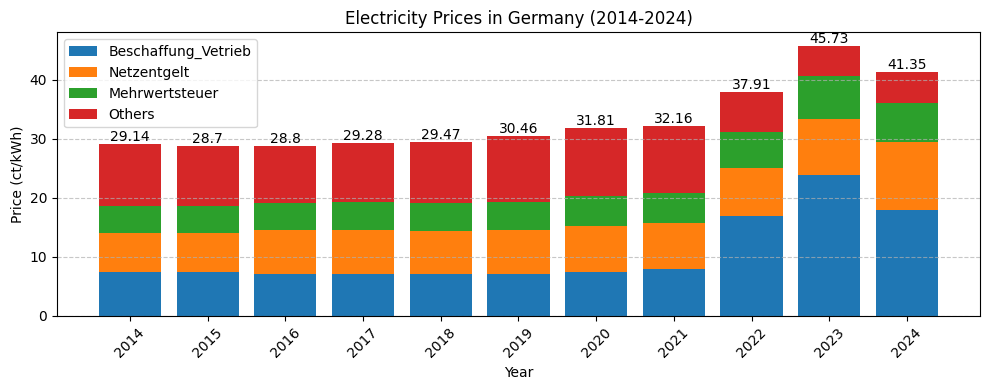

In [366]:
electricity_prices = {
    "Year": [2024, 2023, 2022, 2021, 2020, 2019, 2018, 2017, 2016, 2015, 2014],
    "Beschaffung_Vetrieb": [17.94, 23.83, 16.97, 7.93, 7.51, 7.09, 7.09, 7.05, 7.05, 7.38, 7.38],
    "Netzentgelt": [11.53, 9.52, 8.08, 7.80, 7.75, 7.39, 7.29, 7.51, 7.51, 6.63, 6.63],
    "Mehrwertsteuer": [6.60, 7.30, 6.05, 5.13, 5.08, 4.86, 4.71, 4.67, 4.60, 4.58, 4.56],
    "Summe": [41.35, 45.73, 37.91, 32.16, 31.81, 30.46, 29.47, 29.28, 28.80, 28.70, 29.14]
} #' IN kwH'

# Create DataFrame and add Sonstige column (EEG-Umlage, KWK-Aufschlag, Stromsteuer,...))
electricity_prices_df = pd.DataFrame(electricity_prices)
electricity_prices_df['Sonstige'] = electricity_prices_df['Summe'] - (electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'])
print(electricity_prices_df)

# Plot the data as a stacked bar chart
plt.figure(figsize=(10,4))
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Beschaffung_Vetrieb'], label='Beschaffung_Vetrieb')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Netzentgelt'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'], label='Netzentgelt')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Mehrwertsteuer'], 
        bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'], label='Mehrwertsteuer')
plt.bar(electricity_prices_df['Year'], electricity_prices_df['Sonstige'],bottom=electricity_prices_df['Beschaffung_Vetrieb'] + electricity_prices_df['Netzentgelt'] + electricity_prices_df['Mehrwertsteuer'], label='Others')
plt.xlabel('Year')
plt.ylabel('Price (ct/kWh)')
for i in range(len(electricity_prices_df)):
    plt.text(electricity_prices_df['Year'][i], electricity_prices_df['Summe'][i] + 0.5, str(electricity_prices_df['Summe'][i]), ha='center') #add values
plt.title('Electricity Prices in Germany (2014-2024)')
plt.xticks(electricity_prices_df['Year'], rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Load Household data

- filtered_df = Data of all households in 2019
- filtered_df_test = Data of all households in 2020

In [367]:
#Load pickle into dataframe
hh_path = r"local_input_data\1920 Final Data w. Additional Features HH Hourly Agg.pkl"
start_date = '2019-01-01'
end_date = '2019-12-31'
start_date_test = '2020-01-01'
end_date_test = '2020-12-31'
keyword = 'SFH' # Single Family Households

data_allhouseholds = pd.read_pickle(hh_path)
mask_model = (data_allhouseholds.index >= start_date) & (data_allhouseholds.index < end_date)
mask_test = (data_allhouseholds.index >= start_date_test) & (data_allhouseholds.index < end_date_test)


##### 2019

In [368]:
data_allhouseholds_model = data_allhouseholds.loc[mask_model]

# Extract columns that contain the keyword in their name
filtered_df = data_allhouseholds_model.filter(like=keyword)
filtered_df = filtered_df.drop(columns=['SFH34_P_TOT']) # TODO: SHOW WHY Household 34 is shit

# turn unit to kWh
filtered_df = filtered_df/1000

print("Number of households: ", len(filtered_df.columns))
filtered_df.head()


Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2019-01-01 00:00:00+00:00,0.161493,0.378307,0.555783,0.472945,0.276283,0.141515,1.263900,0.138280,0.167612,0.204542,...,0.187705,0.278985,0.095981,0.091195,0.130055,0.183680,0.172490,0.341785,0.552966,0.137806
2019-01-01 01:00:00+00:00,0.201888,0.379044,0.446765,0.303302,0.254865,0.137292,1.251248,0.109699,0.171209,0.207164,...,0.198733,0.309711,0.097085,0.177395,0.111404,0.080881,0.115421,0.335813,0.326356,0.146449
2019-01-01 02:00:00+00:00,0.156627,0.381565,0.301362,0.142379,0.198773,0.133582,1.121481,0.072142,0.159650,0.214528,...,0.192340,0.399156,0.102519,0.236366,0.118093,0.119899,0.145594,0.211437,0.263901,0.156046
2019-01-01 03:00:00+00:00,0.155399,0.427539,0.307746,0.152653,0.241786,0.147410,0.990431,0.102894,0.124849,0.194947,...,0.224510,0.149937,0.096335,0.186000,0.116369,0.077734,0.112445,0.146979,0.303394,0.176267
2019-01-01 04:00:00+00:00,0.112611,0.309020,0.326347,0.208406,0.165343,0.126375,0.314959,0.091286,0.175570,0.283466,...,0.182807,0.186482,0.095063,0.171690,0.122021,0.076919,0.078177,0.141085,0.290612,0.286422


##### 2020

In [369]:
data_allhouseholds_test = data_allhouseholds.loc[mask_test]

# Extract columns that contain the keyword in their name
filtered_df_test = data_allhouseholds_test.filter(like=keyword)
filtered_df_test = filtered_df_test.drop(columns=['SFH34_P_TOT'])

# turn unit to kWh
filtered_df_test = filtered_df_test/1000

print("Number of households: ", len(filtered_df_test.columns))

filtered_df_test

Number of households:  21


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.163916,0.373391,0.426055,0.175637,0.880133,0.147927,1.028024,0.240754,0.093248,0.596717,...,0.276218,0.344925,0.088926,0.599022,0.111477,0.150296,0.199717,0.149463,0.404039,0.151883
2020-01-01 01:00:00+00:00,0.096884,0.433742,0.414172,0.132504,0.568079,0.142868,0.659489,0.181140,0.120597,1.297585,...,0.233408,0.200887,0.095167,0.585296,0.096038,0.081426,0.206756,0.157918,0.434017,0.151909
2020-01-01 02:00:00+00:00,0.207420,0.455052,0.373124,0.198556,0.641215,0.136044,0.358423,0.109398,0.137314,1.125870,...,0.193405,0.175490,0.103124,0.578868,0.098231,0.083770,0.138144,0.159315,0.546359,0.171845
2020-01-01 03:00:00+00:00,0.109694,0.377600,0.365616,0.150788,0.538791,0.135456,0.349706,0.102048,0.093597,0.299468,...,0.214475,0.146496,0.093065,0.255038,0.100640,0.060413,0.129610,0.138526,0.334807,0.128404
2020-01-01 04:00:00+00:00,0.193015,0.277767,0.374640,0.100247,0.368989,0.145098,0.348721,0.110583,0.123097,0.319027,...,0.205340,0.220397,0.076818,0.161516,0.108735,0.090928,0.077703,0.139926,0.224035,0.150912
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.285882,1.288372,0.487239,0.444430,0.621300,0.287039,1.417525,0.368618,0.992046,0.363517,...,0.299486,1.921150,0.119291,0.597287,0.373720,0.445905,0.541438,0.217190,1.002722,0.271178
2020-12-30 20:00:00+00:00,0.177044,0.443794,0.510834,0.503695,0.597298,0.328044,0.874725,0.298788,0.866079,0.226329,...,0.297135,0.430116,0.114994,0.569243,0.184183,0.223751,0.422432,0.210398,0.553453,0.291510
2020-12-30 21:00:00+00:00,0.240316,0.433245,0.352619,0.454367,0.504256,0.287266,1.038879,0.294333,0.427432,0.178664,...,0.209374,0.404800,0.079628,0.580204,0.197486,0.110087,0.342846,0.187408,0.559419,0.214913


# Models

## 1. Model: Standardlastprofil: 
- Load data: Datensatz: SLP 2019 der Stadtwerke Groß-Gerau Versorgung GmbH: https://ggv-energie.de/cms/netz/allgemeine-daten/netzbilanzierung-download-aller-profile.php
  - Datensatz enthält Standardlastprofil eines typischen Einfamilien Haushalt (H00)
- Vorhersage für 2020, auf Basis des Standardlastprofils
  - Standard Werktag auf Basis vom 
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten



### Load SLP data and normalize to 3000kwh

Load Data

In [370]:
file_path = r"D:\Dokumente\Studium\20242025 WS\WattWise\Repo\wattWise\data\slp\GGV_SLP_1000_MWh_2019_01.xlsx"
sheet_name = "15Min - SLP 2019" # Single Load Profile 2019

data_15min_slp_2019 = pd.read_excel(file_path, sheet_name=sheet_name)
data_15min_slp_2019.head() 

,Messwert-Nr.,Wochentag,Datum,Zeitstempel von,Zeitstempel bis,MP von,MP bis,H00 [kW],H00 [kWh]
0,1,2,2019-01-01,2019-01-01 00:00:00,2019-01-01 00:15:00,00:00,00:15,145.200,36.300
1,2,2,2019-01-01,2019-01-01 00:15:00,2019-01-01 00:30:00,00:15,00:30,140.112,35.028
2,3,2,2019-01-01,2019-01-01 00:30:00,2019-01-01 00:45:00,00:30,00:45,135.720,33.930
3,4,2,2019-01-01,2019-01-01 00:45:00,2019-01-01 01:00:00,00:45,01:00,130.732,32.683
4,5,2,2019-01-01,2019-01-01 01:00:00,2019-01-01 01:15:00,01:00,01:15,127.236,31.809


Data Prepapration

In [371]:
data_15min_slp_2019.drop(columns=['Messwert-Nr.','MP von', 'MP bis'], inplace=True)

In [372]:
#Fasse Zeitstempel pro Stunde zusammen und summiere H00 [kW] in neuer df
data_15min_slp_2019['Time'] = data_15min_slp_2019['Zeitstempel von'].dt.floor('h')

data_slp_hourly_2019 = data_15min_slp_2019.groupby('Time').agg({'H00 [kW]': 'sum'}).reset_index()
data_slp_hourly_2019['H00 [kWh]'] = data_slp_hourly_2019['H00 [kW]'] / 4 
#add 'Wochentag'
data_slp_hourly_2019['Weekday'] = data_slp_hourly_2019['Time'].dt.day_name()

#add Arbeitstag oder Wochenende als neue Spalte
data_slp_hourly_2019['Weekend'] = data_slp_hourly_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

#add Hour and save as int
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Time'].dt.time
data_slp_hourly_2019['Hour'] = data_slp_hourly_2019['Hour'].apply(lambda x: x.hour)

#Normalizing the values to a "average household" with 3000 kWh  
data_slp_hourly_2019['H00_Norm [kWh]'] = data_slp_hourly_2019['H00 [kWh]'] /data_slp_hourly_2019['H00 [kWh]'].sum()*3000

data_slp_hourly_2019

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656
...,...,...,...,...,...,...,...
8754,2019-12-31 19:00:00,656.444,164.111,Tuesday,0,19,0.492333
8755,2019-12-31 20:00:00,574.216,143.554,Tuesday,0,20,0.430662
8756,2019-12-31 21:00:00,557.048,139.262,Tuesday,0,21,0.417786
8757,2019-12-31 22:00:00,640.876,160.219,Tuesday,0,22,0.480657


### Prediction for 2020
auf Basis des Standardlastprofils
  - Standard Werktag berechnen 
  - Standard Wochenende
  - Diese WErte auf Prediciton profil von 2020 übertragen.
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)


In [373]:
#Calculate an average Weekday (Monday - Fridaay means Weekend == 0)
weekday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 0]

average_weekday = weekday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekday.head()

,Hour,H00_Norm [kWh]
0,0,0.263477
1,1,0.231250
2,2,0.221361
3,3,0.219777
4,4,0.227036


Calculate an average Weekday (Monday - Fridaay means Weekend == 0)

In [374]:
#Calculate an average Weekday (Saturday/Sunday means Weekend == 1

weekendday_data = data_slp_hourly_2019[data_slp_hourly_2019['Weekend'] == 1]
average_weekendday = weekendday_data.groupby('Hour').agg({'H00_Norm [kWh]': 'mean'}).reset_index()

average_weekendday.head()

,Hour,H00_Norm [kWh]
0,0,0.279139
1,1,0.241221
2,2,0.226147
3,3,0.219243
4,4,0.217916


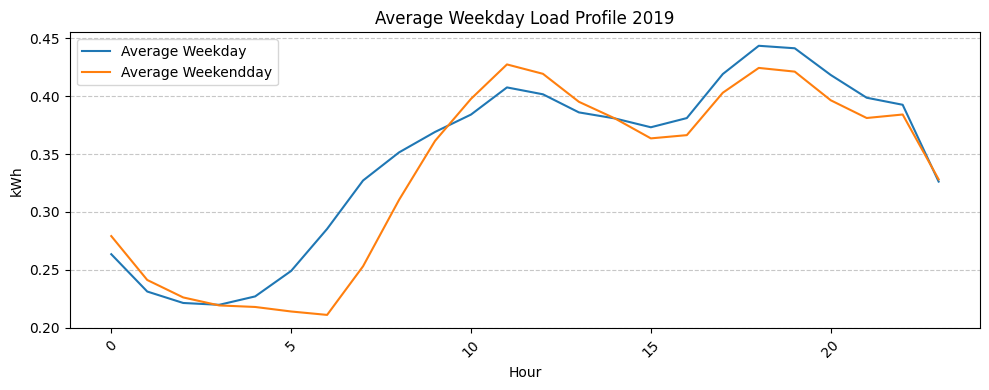

In [375]:
#Plots
#Plot
plt.figure(figsize=(10,4))
plt.plot(average_weekday['Hour'], average_weekday['H00_Norm [kWh]'], label='Average Weekday')
plt.plot(average_weekendday['Hour'], average_weekendday['H00_Norm [kWh]'], label='Average Weekendday')
plt.xlabel('Hour')
plt.ylabel('kWh')
plt.title('Average Weekday Load Profile 2019')
plt.xticks(rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


#### Prediciton profil von 2020 erstellen
- range aufstellen
- if Weekday -> average_weekday matchen zu Kalender auf Basis von Stunden
- if Weekend -> average_weekendday matchen zu Kalender auf Basis von Stunden

In [376]:
# Define the target full-year date range
start_date_2020 = '2020-01-01'
end_date_2020 = '2020-12-31'
date_range = pd.date_range(start=start_date_2020, end=end_date_2020, freq='h', tz='UTC') # hourly data

# Create a DataFrame with the full-year date range
model1_prediciton_2020 = pd.DataFrame(index=date_range)

# add Day informations
model1_prediciton_2020['Hour'] = model1_prediciton_2020.index.hour
model1_prediciton_2020['Weekday'] = model1_prediciton_2020.index.day_name()
model1_prediciton_2020['Weekend'] = model1_prediciton_2020['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)

model1_prediciton_2020['H00_predicted [kWh]']=0
model1_prediciton_2020 = model1_prediciton_2020[:-1] #delete last row (0Uhr)

model1_prediciton_2020.head()

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0
2020-01-01 01:00:00+00:00,1,Wednesday,0,0
2020-01-01 02:00:00+00:00,2,Wednesday,0,0
2020-01-01 03:00:00+00:00,3,Wednesday,0,0
2020-01-01 04:00:00+00:00,4,Wednesday,0,0


In [377]:
# add information for model1_prediciton_2020['H00_predicted [kWh]']. If Weekday == 0 then take average_weekday else average_weekendday and match with Hour
for index, row in model1_prediciton_2020.iterrows():
    if row['Weekend'] == 0:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]
    else:
        model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekendday[average_weekendday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\2267906313.py:4: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.2634770519382463' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model1_prediciton_2020.loc[index, 'H00_predicted [kWh]'] = average_weekday[average_weekday['Hour'] == row['Hour']]['H00_Norm [kWh]'].values[0]


In [378]:
model1_prediciton_2020

,Hour,Weekday,Weekend,H00_predicted [kWh]
2020-01-01 00:00:00+00:00,0,Wednesday,0,0.263477
2020-01-01 01:00:00+00:00,1,Wednesday,0,0.231250
2020-01-01 02:00:00+00:00,2,Wednesday,0,0.221361
2020-01-01 03:00:00+00:00,3,Wednesday,0,0.219777
2020-01-01 04:00:00+00:00,4,Wednesday,0,0.227036
...,...,...,...,...
2020-12-30 19:00:00+00:00,19,Wednesday,0,0.441350
2020-12-30 20:00:00+00:00,20,Wednesday,0,0.418301
2020-12-30 21:00:00+00:00,21,Wednesday,0,0.398629
2020-12-30 22:00:00+00:00,22,Wednesday,0,0.392547


### Test the model	
- Vergleich mit realem Datensatz von allen Haushalten. Berechne MAPE
- Preisberechnugn für 2020

In [379]:
# Define actual_load_profile2020
actual_load_profile2020 = filtered_df_test

# Display the actual load profile for 2020
actual_load_profile2020.head()

#Normalize to 3000 kWh
for column in actual_load_profile2020.columns:
    actual_load_profile2020[column] = actual_load_profile2020[column] / actual_load_profile2020[column].sum() * 3000

# Display the actual load profile for 2020
actual_load_profile2020.head()

,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
date,,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:00:00+00:00,0.235083,0.338549,0.421355,0.165795,0.536347,0.130392,1.260980,0.312827,0.100835,0.529366,...,0.316237,0.288901,0.238178,0.565123,0.230555,0.195297,0.216712,0.168074,0.314421,0.188607
2020-01-01 01:00:00+00:00,0.138948,0.393269,0.409602,0.125080,0.346184,0.125933,0.808933,0.235367,0.130411,1.151129,...,0.267225,0.168259,0.254894,0.552174,0.198624,0.105806,0.224350,0.177582,0.337750,0.188640
2020-01-01 02:00:00+00:00,0.297474,0.412591,0.369007,0.187430,0.390752,0.119917,0.439644,0.142148,0.148487,0.998795,...,0.221426,0.146986,0.276205,0.546109,0.203159,0.108852,0.149899,0.179153,0.425174,0.213396
2020-01-01 03:00:00+00:00,0.157319,0.342366,0.361583,0.142339,0.328336,0.119399,0.428951,0.132597,0.101213,0.265667,...,0.245548,0.122702,0.249265,0.240605,0.208143,0.078502,0.140639,0.155775,0.260545,0.159452
2020-01-01 04:00:00+00:00,0.276814,0.251848,0.370506,0.094630,0.224859,0.127898,0.427743,0.143687,0.133114,0.283019,...,0.235090,0.184600,0.205749,0.152376,0.224884,0.118153,0.084315,0.157349,0.174343,0.187402


In [380]:
# NMAE
def calculate_nmae(actual_df, predicted_df):
    """
    Calculate the Normalized Mean Absolute Error (NMAE) between actual and predicted values.

    Parameters:
    - actual_df (pd.DataFrame or pd.Series): The DataFrame or Series containing actual values.
    - predicted_df (pd.DataFrame or pd.Series): The DataFrame or Series containing predicted values.

    Returns:
    - float: The NMAE value as a percentage.
    """
    if not actual_df.index.equals(predicted_df.index):
        raise ValueError("The indices of actual_df and predicted_df must match.")
    absolute_errors = abs(actual_df - predicted_df)
    mae = absolute_errors.mean() # Compute the Mean Absolute Error (MAE)
    nmae = mae / actual_df.mean() # Compute the Normalized Mean Absolute Error (NMAE)
    return 100 * nmae

nmae_sum = 0
for column in actual_load_profile2020.columns:
    nmae = calculate_nmae(actual_load_profile2020[column], model1_prediciton_2020['H00_predicted [kWh]'])
    print(f"NMAE for {column}: {nmae:.2f} %")
    nmae_sum = nmae_sum + nmae

print(f"Average NMAE: {nmae_sum/len(actual_load_profile2020.columns):.2f} %")


NMAE for SFH3_P_TOT: 58.07 %
NMAE for SFH4_P_TOT: 39.39 %
NMAE for SFH5_P_TOT: 50.62 %
NMAE for SFH7_P_TOT: 50.45 %
NMAE for SFH9_P_TOT: 62.75 %
NMAE for SFH12_P_TOT: 67.07 %
NMAE for SFH14_P_TOT: 60.65 %
NMAE for SFH16_P_TOT: 69.87 %
NMAE for SFH18_P_TOT: 71.88 %
NMAE for SFH19_P_TOT: 43.41 %
NMAE for SFH20_P_TOT: 49.42 %
NMAE for SFH21_P_TOT: 37.17 %
NMAE for SFH22_P_TOT: 48.06 %
NMAE for SFH27_P_TOT: 34.20 %
NMAE for SFH28_P_TOT: 57.14 %
NMAE for SFH29_P_TOT: 52.29 %
NMAE for SFH30_P_TOT: 61.87 %
NMAE for SFH32_P_TOT: 48.67 %
NMAE for SFH36_P_TOT: 54.38 %
NMAE for SFH38_P_TOT: 33.25 %
NMAE for SFH39_P_TOT: 35.44 %
Average NMAE: 51.72 %


#### Cost Comparison
- price calculation 2020 (dynamic, static prices)
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices)
- Auswertung

In [381]:
spot_prices_2020
#use 'Date (CET' as index
spot_prices_2020.set_index('Date (CET)', inplace=True)
spot_prices_2020


,Price (€/MWh),Price ct/KWH
Date (CET),,
2020-01-01 00:00:00,41.88,4.188
2020-01-01 01:00:00,38.60,3.860
2020-01-01 02:00:00,36.55,3.655
2020-01-01 03:00:00,32.32,3.232
2020-01-01 04:00:00,30.85,3.085
...,...,...
2020-12-30 19:00:00,53.60,5.360
2020-12-30 20:00:00,52.38,5.238
2020-12-30 21:00:00,46.88,4.688


In [382]:
# Preisberechnung

# Define the missing variables # TODO: Replace with actual values
consumption_dependent_fixed_costs = 19.71  # ct per KwH 2024 value Tibber - Example value, replace with actual value
Consumption_independent_base_price = 15.73  # €/Monat - 2024 value Tibber - Example value, replace with actual value

# Calculate dynamic price in 2020 und rechne Cent in euro
dynamic_price_per_kwh_2020 = (spot_prices_2020['Price ct/KWH'] + consumption_dependent_fixed_costs)/100
dynamic_price_permonth = Consumption_independent_base_price # ist schon in Euro!

# Calculate fixed price in 2020
fixed_price_per_kwh = electricity_prices_df.loc[electricity_prices_df['Year'] == 2020, 'Summe'].values[0]/100 # /100, damit in Euro
print("Fixed price per kWh in 2020 [Euro] : ", fixed_price_per_kwh)

Fixed price per kWh in 2020 [Euro] :  0.3181


##### Actual Costs

In [383]:
# Calculate the annual costs for each household based on dynamic price

def calculate_annual_dynamic_costs(df_load_profile, df_dynamic_price):
    # Ensure both indices are timezone-aware
    if df_load_profile.index.tz is None:
        df_load_profile.index = df_load_profile.index.tz_localize('UTC')
    if df_dynamic_price.index.tz is None:
        df_dynamic_price.index = df_dynamic_price.index.tz_localize('UTC')
    
    # Calculate the total costs of the household
    annual_costs = ((df_load_profile * df_dynamic_price).sum(axis=0))
    return annual_costs

# Calculate the annual costs for each household based on static price
def calculate_annual_static_costs(df_load_profile, static_price_per_kwh):
    
    annual_costs = (df_load_profile.sum(axis=0) * static_price_per_kwh)

    return annual_costs

In [384]:
# Calculate the annual costs for each household and compare fixed and dynamic prices

print("------Result------")

sum_difference = 0
list_of_households_fixed_cheaper = []
list_of_households_dynamic_cheaper = []

for column in actual_load_profile2020.columns:
    print(f"Household: ", column)
    annual_costs_dynamic = calculate_annual_dynamic_costs(actual_load_profile2020[column], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
    print(f"Annual actual costs for {column} based on dynamic prices: {annual_costs_dynamic:.2f} €")
    annual_costs_static = calculate_annual_static_costs(actual_load_profile2020[column], fixed_price_per_kwh)#in €
    print(f"Annual actual costs for {column} based on fixed prices: {annual_costs_static:.2f} €")

    
    if annual_costs_dynamic < annual_costs_static:
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_costs_static - annual_costs_dynamic, "Euro")
        list_of_households_dynamic_cheaper.append(column)
    else:
        print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_costs_dynamic - annual_costs_static, "Euro")
        list_of_households_fixed_cheaper.append(column)
   

print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)


------Result------
Household:  SFH3_P_TOT
Annual actual costs for SFH3_P_TOT based on dynamic prices: 867.47 €
Annual actual costs for SFH3_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  86.83484099337579 Euro
Household:  SFH4_P_TOT
Annual actual costs for SFH4_P_TOT based on dynamic prices: 874.87 €
Annual actual costs for SFH4_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.43267412409489 Euro
Household:  SFH5_P_TOT
Annual actual costs for SFH5_P_TOT based on dynamic prices: 873.21 €
Annual actual costs for SFH5_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  81.08646848293427 Euro
Household:  SFH7_P_TOT
Annual actual costs for SFH7_P_TOT based on dynamic prices: 878.49 €
Annual actual costs for SFH7_P_TOT based on fixed prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  75.81451859732431 Euro
Household:  S

##### Predicted costs



In [385]:
annual_predicted_costs_dynamic_prices = calculate_annual_dynamic_costs(model1_prediciton_2020['H00_predicted [kWh]'], dynamic_price_per_kwh_2020) + dynamic_price_permonth*12 #in €
print(f"Annual predicted costs based on dynamic prices: {annual_predicted_costs_dynamic_prices:.2f} €")

annual_predicted_costs_static_prices = calculate_annual_static_costs(model1_prediciton_2020['H00_predicted [kWh]'], fixed_price_per_kwh) #in €
print(f"Annual predicted costs based on fixed prices: {annual_predicted_costs_static_prices:.2f} €")

if annual_predicted_costs_dynamic_prices < annual_predicted_costs_static_prices:
    print("Dynamic pricing is cheaper than fixed pricing. Difference: ", annual_predicted_costs_static_prices - annual_predicted_costs_dynamic_prices, "Euro")
    print("Wrong predicted households: ", list_of_households_fixed_cheaper)
else:
    print("Fixed pricing is cheaper than dynamic pricing. Difference: ", annual_predicted_costs_dynamic_prices - annual_predicted_costs_static_prices, "Euro")
    print("Wrong predicted households: ", list_of_households_dynamic_cheaper)




Annual predicted costs based on dynamic prices: 874.58 €
Annual predicted costs based on fixed prices: 954.38 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.80064741871627 Euro
Wrong predicted households:  []


##### NMAE

In [386]:
# Calculate NMAE dynamic prices
# TODO: Calculate NMAE for dynamic prices

## 2. Model Predict Load Profile of household based on Standardlastprofil and two week load profile of the household

- Daten nutze: 
  - Reuse *model1_prediciton_2020* von Model 1. Dieses Modell nutzt das SLP von 2019 zur Vorhersage von 2020 auf Basis von Werktagen vs Wochenendtagen. 
  - Random two week load of the specific household aus 2019: *random_two_week_load*
  
- Vorhersage für 2020, auf Basis des Standardlastprofil und Random two week load of the specific household
  - Standard Werktag
  - Standard Wochenende
  - Verbrauch des Haushalts von 2019 erfragen (hier irrelevant, da alle auf 3000 normiert sind)
  - 
- Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *filtered_df_test*
  - Forecast Datensatz: *model2_prediction_2020*
- Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten

Definiere Funktionen
- *filter_two_week_data*: This function filters the given household load dataset for a specific two-week period defined by the start_date and end_date.
- *determine_season*: This function determines the season based on the provided date.
- 

In [387]:
def filter_two_week_data(df_houshold_load_2019, start_date, end_date):
    return df_houshold_load_2019.loc[start_date:end_date]

def determine_season(date):
    month = date.month
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    



### Daten erstellen
- Two week data set: *filtered_df_2_weeks_2019* für alle Haushalte
- Average weekdays out *filtered_df_2_weeks_2019*: *average_weekdays_allhousholds*
- Average weekenddays out *filtered_df_2_weeks_2019*: *average_weekenddays_allhousholds*

In [388]:
random_start_date = random.choice(pd.date_range(pd.Timestamp(start_date), pd.Timestamp(end_date) - pd.Timedelta(days=14), tz='UTC'))
random_end_date = random_start_date + pd.Timedelta(days=14)

Filtert nach 2 Wochen.  
Berechnet aus deiser Woche für alle Haushalte den Average Weekend und Weekday WErt für alle 24 Stunden.

In [389]:
# Filtere nach 2 Woche, lösche letzte Reihe (0Uhr)
filtered_df_2_weeks_2019 = filter_two_week_data(filtered_df, random_start_date, random_end_date)
filtered_df_2_weeks_2019 = filtered_df_2_weeks_2019[:-1]

# Determine Season
season = determine_season(random_start_date)
print("Random 2 weeks in 2019: ", random_start_date, " - ", random_end_date)
print("Season: ", season)
filtered_df_2_weeks_2019

# Add column with information on Weekday or Weekend. Wenn 1, dann Wochenende. Sonst 0.
filtered_df_2_weeks_2019['Weekday'] = filtered_df_2_weeks_2019.index.day_name()
filtered_df_2_weeks_2019['Weekend'] = filtered_df_2_weeks_2019['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
filtered_df_2_weeks_2019.drop(columns=['Weekday'], inplace=True)

# Add Hour column
filtered_df_2_weeks_2019['Hour'] = filtered_df_2_weeks_2019.index.hour

# Calculate the average load profile for the 2 weeks for a workday or a weekend day
# Calculate an average Weekday (Monday - Fridaay means Weekend == 0) per column and save them in a new df
filtered_df_2_weeks_weekday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 0]
average_weekdays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekday = filtered_df_2_weeks_weekday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekdays_allhousholds[column] = average_weekday[column]

average_weekdays_allhousholds

# Calculate an average Weekendday (Saturday/Sunday means Weekend == 1) per column and save them in a new df
filtered_df_2_weeks_weekendday_data = filtered_df_2_weeks_2019[filtered_df_2_weeks_2019['Weekend'] == 1]
average_weekenddays_allhousholds = pd.DataFrame()
for column in filtered_df_2_weeks_weekendday_data.columns:
    if column not in ['Weekend', 'Hour']:
        average_weekendday = filtered_df_2_weeks_weekendday_data.groupby('Hour').agg({column: 'mean'}).reset_index()
        average_weekenddays_allhousholds[column] = average_weekendday[column]

average_weekenddays_allhousholds.head()
    

Random 2 weeks in 2019:  2019-03-13 00:00:00+00:00  -  2019-03-27 00:00:00+00:00
Season:  Spring


,SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,SFH14_P_TOT,SFH16_P_TOT,SFH18_P_TOT,SFH19_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
0,0.160152,0.239740,0.292295,0.149909,0.207286,0.121938,0.086671,0.108206,0.126547,0.235896,...,0.191465,0.192808,0.097523,0.128803,0.097564,0.079846,0.161856,0.314266,0.310965,0.163814
1,0.120195,0.241805,0.259687,0.146501,0.187885,0.121846,0.087183,0.120161,0.123376,0.223903,...,0.199180,0.189941,0.100396,0.138914,0.093580,0.080434,0.151441,0.273010,0.264145,0.156976
2,0.181661,0.253995,0.250594,0.168473,0.211204,0.121904,0.093276,0.111472,0.127433,0.274386,...,0.198779,0.178633,0.104512,0.156768,0.087597,0.078484,0.107351,0.176234,0.282835,0.152180
3,0.146585,0.272943,0.237199,0.156029,0.235508,0.117460,0.097769,0.119379,0.136472,0.234984,...,0.201643,0.172397,0.098730,0.126701,0.102008,0.076711,0.103058,0.195126,0.285632,0.161017
4,0.174044,0.268843,0.212556,0.151867,0.159926,0.117063,0.097525,0.105964,0.138975,0.233722,...,0.188516,0.187403,0.095050,0.117879,0.084816,0.078737,0.078329,0.184539,0.266124,0.154191


### Prediction for 2020

Remember: 
- *average_weekenddays_allhousholds*: granular short-term data set
- *average_weekdays_allhousholds*: granular short-term data set
- *model1_prediciton_2020*: long-term seasonality and daily patterns 

Create a weighted sum of the two datasets: 
- Assigning higher weight to the two-week load profile for capturing recent trends. 
- Using the model1_prediciton_2020 load profile for long-term corrections.

In [390]:
# Create a DataFrame with the full-year date range as index by expanidng the two week data and adding the data from model1_prediciton_2020
start_date_1 = '2020-01-01' # TODO : Hier muss noch das Datum nach den zwei Wochen stehen, allerdings habe ich noch keine Idee, wie wir das machen können.
end_date_1 = '2020-12-31' 
date_range = pd.date_range(start=start_date_test, end=end_date_test, freq='h', tz='UTC') # hourly data

model2_prediction_2020_preparation = pd.DataFrame(index=date_range)
model2_prediction_2020_preparation = model2_prediction_2020_preparation[:-1] # delete last row (0Uhr)
model2_prediction_2020_preparation['Hour'] = model2_prediction_2020_preparation.index.hour # add Hour column
model2_prediction_2020_preparation['Weekday'] = model2_prediction_2020_preparation.index.day_name() # add Weekday column
model2_prediction_2020_preparation['Weekend'] = model2_prediction_2020_preparation['Weekday'].apply(lambda x: 1 if x in ['Saturday', 'Sunday'] else 0)
model2_prediction_2020_preparation.drop(columns=['Weekday'], inplace=True) # drop Weekday column, we dont need it anymore. 0 and 1 is enough
model2_prediction_2020_preparation['Season'] = model2_prediction_2020_preparation.index.map(determine_season) # add Season column

# add information of mode1_prediction_2020['H00_predicted [kWh]']
model2_prediction_2020_preparation['H00_predicted [kWh]'] = model1_prediciton_2020['H00_predicted [kWh]']

for column in average_weekenddays_allhousholds:
    # Wenn model2_prediction_2020_preparation[Weekend] == 0, dann nimm average_weekdays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 0, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 0]['Hour'].map(average_weekdays_allhousholds[column])
    # Wenn model2_prediction_2020_preparation[Weekend] == 1, dann nimm average_weekenddays_allhousholds[column] und matche mit Hour
    model2_prediction_2020_preparation.loc[model2_prediction_2020_preparation['Weekend'] == 1, column] = model2_prediction_2020_preparation[model2_prediction_2020_preparation['Weekend'] == 1]['Hour'].map(average_weekenddays_allhousholds[column])

model2_prediction_2020_preparation.head()


,Hour,Weekend,Season,H00_predicted [kWh],SFH3_P_TOT,SFH4_P_TOT,SFH5_P_TOT,SFH7_P_TOT,SFH9_P_TOT,SFH12_P_TOT,...,SFH21_P_TOT,SFH22_P_TOT,SFH27_P_TOT,SFH28_P_TOT,SFH29_P_TOT,SFH30_P_TOT,SFH32_P_TOT,SFH36_P_TOT,SFH38_P_TOT,SFH39_P_TOT
2020-01-01 00:00:00+00:00,0,0,Winter,0.263477,0.148756,0.263886,0.309305,0.157488,0.202513,0.122120,...,0.203440,0.189608,0.097165,0.134352,0.087596,0.083279,0.156974,0.207410,0.280878,0.173924
2020-01-01 01:00:00+00:00,1,0,Winter,0.231250,0.134566,0.238767,0.268820,0.154072,0.189217,0.123588,...,0.213091,0.166640,0.097311,0.133185,0.093014,0.075719,0.127568,0.175681,0.239667,0.187985
2020-01-01 02:00:00+00:00,2,0,Winter,0.221361,0.176692,0.244250,0.265322,0.127181,0.193572,0.125009,...,0.196371,0.186440,0.105655,0.142419,0.090577,0.080510,0.101351,0.159389,0.289237,0.176625
2020-01-01 03:00:00+00:00,3,0,Winter,0.219777,0.166568,0.260903,0.222577,0.149364,0.189975,0.122950,...,0.200665,0.175283,0.094160,0.143519,0.087253,0.082114,0.109326,0.153679,0.279235,0.166288
2020-01-01 04:00:00+00:00,4,0,Winter,0.227036,0.198625,0.280270,0.216492,0.156657,0.963209,0.157853,...,0.199243,0.218753,0.096116,0.132908,0.092570,0.136135,0.062626,0.143067,0.249361,0.192314


In [391]:
#Merge H00_predicted [kWh] with two week data (rows (SFH1 - SFH33)

# predict the load using weighted averages # TODO: Hier noch mehr weights ausprobieren. Was ist das beste?
# differentiate between offseason and season

weight_offseason_twoweeks = 0.5
weight_offseason_SLP = 0.5

weight_twoweeks = 0.7
weight_SLP = 0.3

for index, row in model2_prediction_2020_preparation.iterrows():
    if row['Season'] == season:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_twoweeks * row[column] + weight_SLP * row['H00_predicted [kWh]']
    else:
        for column in average_weekenddays_allhousholds:
            model2_prediction_2020_preparation.at[index, column + "_Prediction"] = weight_offseason_twoweeks * row[column] + weight_offseason_SLP * row['H00_predicted [kWh]']


In [392]:
# Drop average_weekenddays_allhousholds columns out of model2_prediction_2020
columnstodrop = list(average_weekenddays_allhousholds.columns)

model2_prediction_2020 = model2_prediction_2020_preparation
model2_prediction_2020.drop(columns=columnstodrop, inplace=True)
model2_prediction_2020.drop(columns=['Hour', 'Weekend', 'Season', 'H00_predicted [kWh]'], inplace=True)
model2_prediction_2020.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.206116,0.263681,0.286391,0.210482,0.232995,0.192798,0.194654,0.190901,0.213702,0.258764,...,0.233459,0.226542,0.180321,0.198914,0.175537,0.173378,0.210226,0.235443,0.272178,0.218701
2020-01-01 01:00:00+00:00,0.182908,0.235008,0.250035,0.192661,0.210234,0.177419,0.176447,0.171722,0.196672,0.234005,...,0.222170,0.198945,0.164280,0.182218,0.162132,0.153485,0.179409,0.203466,0.235459,0.209617
2020-01-01 02:00:00+00:00,0.199026,0.232805,0.243341,0.174271,0.207466,0.173185,0.173861,0.167965,0.193885,0.235773,...,0.208866,0.203900,0.163508,0.181890,0.155969,0.150935,0.161356,0.190375,0.255299,0.198993
2020-01-01 03:00:00+00:00,0.193173,0.240340,0.221177,0.184571,0.204876,0.171363,0.171783,0.166663,0.205367,0.234739,...,0.210221,0.197530,0.156968,0.181648,0.153515,0.150946,0.164552,0.186728,0.249506,0.193032
2020-01-01 04:00:00+00:00,0.212831,0.253653,0.221764,0.191847,0.595123,0.192445,0.173640,0.238324,0.207540,0.237162,...,0.213140,0.222895,0.161576,0.179972,0.159803,0.181585,0.144831,0.185052,0.238199,0.209675


In [393]:
#NOrmalize predicted data to 3000kWh
for column in model2_prediction_2020:
    sum_predicted_load = model2_prediction_2020[column].sum()
    model2_prediction_2020[column] = model2_prediction_2020[column] /sum_predicted_load *3000

### Test the Model: 
#### Vergleich Load Forecast mit realem Datensatz von allen Haushalten 2020
  - Realer Datensatz: *filtered_df_test*
  - Forecast Datensatz: *model2_prediction_2020*

In [394]:
# Calculate NMAE for each SFH column
nmae_results = {}
for column in filtered_df_test.columns:
    nmae = calculate_nmae(filtered_df_test[column], model2_prediction_2020[column + '_Prediction'])
    nmae_results[column] = nmae
    print(f"NMAE for {column}: {nmae:.2f} %")
nmae_average = sum(nmae_results.values())/len(nmae_results)
nmae_average

NMAE for SFH3_P_TOT: 53.31 %
NMAE for SFH4_P_TOT: 38.24 %
NMAE for SFH5_P_TOT: 51.05 %
NMAE for SFH7_P_TOT: 48.36 %
NMAE for SFH9_P_TOT: 57.00 %
NMAE for SFH12_P_TOT: 62.29 %
NMAE for SFH14_P_TOT: 57.72 %
NMAE for SFH16_P_TOT: 67.36 %
NMAE for SFH18_P_TOT: 65.04 %
NMAE for SFH19_P_TOT: 37.62 %
NMAE for SFH20_P_TOT: 48.89 %
NMAE for SFH21_P_TOT: 37.77 %
NMAE for SFH22_P_TOT: 49.32 %
NMAE for SFH27_P_TOT: 34.73 %
NMAE for SFH28_P_TOT: 51.39 %
NMAE for SFH29_P_TOT: 51.22 %
NMAE for SFH30_P_TOT: 56.18 %
NMAE for SFH32_P_TOT: 42.58 %
NMAE for SFH36_P_TOT: 50.38 %
NMAE for SFH38_P_TOT: 31.84 %
NMAE for SFH39_P_TOT: 35.62 %


np.float64(48.947031507080965)

#### Vergleich Jahreskosten mit realem Datensatz und Forecast von 2020 von allen Haushalten
- price calculation 2020 (dynamic, static prices): können wir von Model1 übernehmen
  Dynamisch
  - dynamic_price_per_kwh_2020
  - dynamic_price_permonth
  Fixed
  - fixed_price_per_kwh
- 
- Predicted costs (dynamic, static prices)
- actual costs (dynamic, static prices): können wir von Model1 übernehmen
- Auswertung

### Auswertung

Actual Costs

In [395]:
print("List of households where fixed pricing is cheaper than dynamic pricing: ", list_of_households_fixed_cheaper)
print("List of households where dynamic pricing is cheaper than fixed pricing: ", list_of_households_dynamic_cheaper)


List of households where fixed pricing is cheaper than dynamic pricing:  []
List of households where dynamic pricing is cheaper than fixed pricing:  ['SFH3_P_TOT', 'SFH4_P_TOT', 'SFH5_P_TOT', 'SFH7_P_TOT', 'SFH9_P_TOT', 'SFH12_P_TOT', 'SFH14_P_TOT', 'SFH16_P_TOT', 'SFH18_P_TOT', 'SFH19_P_TOT', 'SFH20_P_TOT', 'SFH21_P_TOT', 'SFH22_P_TOT', 'SFH27_P_TOT', 'SFH28_P_TOT', 'SFH29_P_TOT', 'SFH30_P_TOT', 'SFH32_P_TOT', 'SFH36_P_TOT', 'SFH38_P_TOT', 'SFH39_P_TOT']


Predicted Costs

In [396]:
annual_predicted_costs_dynamic_prices_results_m2 = {}
annual_predicted_costs_static_prices_results_m2 = {}

for column in filtered_df_test: 
    print("Result Houshold: ", column)
    result_dynamic = calculate_annual_dynamic_costs(model2_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m2[column] = result_dynamic
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic:.2f} €")

    result_static = calculate_annual_static_costs(model2_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m2 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")

    if result_dynamic < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic-result_static, "Euro")



Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 872.54 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  81.7609322239507 Euro
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 875.06 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.24266916192062 Euro
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 874.91 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  79.3943349828271 Euro
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 876.62 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  77.67576919972555 Euro
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 873.68 €
Annual predicted

In [397]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []


## 3. Model: SLP und Monatsinfos von Datensatz

Idea: 
- SLP data as monthly as monthly profile
- 2 week dataset as daily profile. Hoch und runterrechnen auf Monatswerte.


### Load data

Two week dataprofile for one year.

In [398]:
prediciton_base_based_on_two_weekdata = model2_prediction_2020_preparation #already normed
prediciton_base_based_on_two_weekdata.head()

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.247092,0.239770,0.264658,0.202602,0.170647,0.192892,0.230643,0.197712,0.209064,0.241712,...,0.242481,0.215805,0.264087,0.198703,0.240099,0.222847,0.221018,0.225624,0.237467,0.265800
2020-01-01 01:00:00+00:00,0.219270,0.213697,0.231061,0.185448,0.153976,0.177505,0.209070,0.177848,0.192404,0.218585,...,0.230756,0.189516,0.240596,0.182024,0.221764,0.197278,0.188619,0.194980,0.205431,0.254761
2020-01-01 02:00:00+00:00,0.238593,0.211694,0.224875,0.167746,0.151950,0.173269,0.206006,0.173957,0.189678,0.220236,...,0.216937,0.194236,0.239464,0.181696,0.213334,0.194001,0.169639,0.182435,0.222741,0.241848
2020-01-01 03:00:00+00:00,0.231575,0.218545,0.204393,0.177660,0.150052,0.171447,0.203544,0.172609,0.200910,0.219271,...,0.218345,0.188168,0.229887,0.181454,0.209978,0.194014,0.173000,0.178940,0.217687,0.234604
2020-01-01 04:00:00+00:00,0.255141,0.230651,0.204935,0.184664,0.435871,0.192538,0.205744,0.246827,0.203036,0.221534,...,0.221376,0.212331,0.236635,0.179780,0.218578,0.233396,0.152267,0.177334,0.207822,0.254831


In [399]:
#Fasse Zeitstempel pro Monat zusammen 
prediciton_base_based_on_two_weekdata_monthly = prediciton_base_based_on_two_weekdata.groupby(prediciton_base_based_on_two_weekdata.index.to_period('M')).agg('sum')
prediciton_base_based_on_two_weekdata_monthly.head()

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\3805761374.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  prediciton_base_based_on_two_weekdata_monthly = prediciton_base_based_on_two_weekdata.groupby(prediciton_base_based_on_two_weekdata.index.to_period('M')).agg('sum')


,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01,258.075412,253.343065,252.966500,254.436924,249.332715,254.073908,259.940000,256.349268,253.834753,252.851283,...,255.146796,252.606304,265.765266,254.120055,263.598422,261.047430,256.150834,253.561024,252.007529,259.970468
2020-02,243.817702,235.814719,236.739206,237.100529,231.855827,238.968176,241.689845,238.524236,238.251779,237.247560,...,239.648870,238.215190,248.376383,238.865705,246.189566,244.911836,239.336008,237.654312,235.407180,242.921967
2020-03,241.348053,260.921250,260.065025,257.268987,273.143828,254.934054,241.800416,252.158103,256.405482,259.454446,...,252.249184,258.331298,222.599367,255.022251,229.277244,235.134241,251.205079,257.745658,263.583487,239.849242
2020-04,231.900743,253.208670,251.542220,249.498004,265.186698,245.788965,234.877099,244.785608,247.537527,250.546786,...,243.399358,248.674127,215.462781,245.969880,222.037542,226.985540,243.208478,249.059768,255.236254,232.197718
2020-05,243.689807,259.928918,260.253294,256.524962,271.940519,256.232405,240.565070,251.084888,257.246441,260.212766,...,253.253521,260.196799,222.537312,256.185944,229.056950,235.928581,251.054605,258.269155,263.364430,239.728697


SLP monthly basis


In [400]:
data_slp_hourly_2019.head()

,Time,H00 [kW],H00 [kWh],Weekday,Weekend,Hour,H00_Norm [kWh]
0,2019-01-01 00:00:00,551.764,137.941,Tuesday,0,0,0.413823
1,2019-01-01 01:00:00,492.584,123.146,Tuesday,0,1,0.369438
2,2019-01-01 02:00:00,448.376,112.094,Tuesday,0,2,0.336282
3,2019-01-01 03:00:00,418.236,104.559,Tuesday,0,3,0.313677
4,2019-01-01 04:00:00,386.208,96.552,Tuesday,0,4,0.289656


In [401]:
#Fasse Zeitstempel pro Monat zusammen und summiere H00_Norm [kW] in neuer df
data_slp_monthly_2019 = data_slp_hourly_2019.groupby(data_slp_hourly_2019['Time'].dt.to_period('M')).agg({'H00_Norm [kWh]': 'sum'}).reset_index()


print("Sum of data_slp_monthly_2019", data_slp_monthly_2019['H00_Norm [kWh]'].sum())

#data_slp_monthly_2019['H00_monthlypercentage'] = data_slp_monthly_2019['H00_Norm [kWh]'] / data_slp_monthly_2019['H00_Norm [kWh]'].sum() 

data_slp_monthly_2019

#Time: add one year.
data_slp_monthly_2019['Time'] = data_slp_monthly_2019['Time'].apply(lambda x: x + 12)
# Time as index
data_slp_monthly_2019.set_index('Time', inplace=True)


#Save H00_Norm [kWh] as int64
data_slp_monthly_2019['H00_Norm [kWh]'] = data_slp_monthly_2019['H00_Norm [kWh]'].astype('int64')

data_slp_monthly_2019

Sum of data_slp_monthly_2019 3000.0


,H00_Norm [kWh]
Time,
2020-01,299
2020-02,257
2020-03,249
2020-04,227
2020-05,226
2020-06,203
2020-07,197
2020-08,215
2020-09,225


Coefficients

In [402]:
# per housheold (= column): SLP_monthly(month)/ 2weekprediciton(month)
montly_coefficients = pd.DataFrame(index=prediciton_base_based_on_two_weekdata_monthly.index)

for household in prediciton_base_based_on_two_weekdata_monthly.columns:
    for month in prediciton_base_based_on_two_weekdata_monthly.index:
        montly_coefficients.at[month, household] = data_slp_monthly_2019.at[month, 'H00_Norm [kWh]'] / prediciton_base_based_on_two_weekdata_monthly.at[month, household] 

montly_coefficients.head()



,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01,1.158576,1.180218,1.181975,1.175144,1.199201,1.176823,1.150265,1.166377,1.177932,1.182513,...,1.171874,1.183660,1.125053,1.176609,1.134301,1.145386,1.167281,1.179203,1.186472,1.150131
2020-02,1.054066,1.089839,1.085583,1.083928,1.108447,1.075457,1.063346,1.077459,1.078691,1.083257,...,1.072402,1.078856,1.034720,1.075918,1.043911,1.049357,1.073804,1.081403,1.091725,1.057953
2020-03,1.031705,0.954311,0.957453,0.967859,0.911608,0.976723,1.029775,0.987476,0.971118,0.959706,...,0.987119,0.963879,1.118602,0.976385,1.086021,1.058970,0.991222,0.966069,0.944672,1.038152
2020-04,0.978867,0.896494,0.902433,0.909827,0.856001,0.923557,0.966463,0.927342,0.917033,0.906018,...,0.932624,0.912841,1.053546,0.922877,1.022350,1.000064,0.933356,0.911428,0.889372,0.977615
2020-05,0.927409,0.869468,0.868385,0.881006,0.831064,0.882012,0.939455,0.900094,0.878535,0.868520,...,0.892386,0.868573,1.015560,0.882172,0.986654,0.957917,0.900203,0.875056,0.858127,0.942732


### Prediction for 2020

Model 3 Prediciton Framwork

In [403]:
model3_prediction_2020 = pd.DataFrame(index=date_range)
model3_prediction_2020 = model3_prediction_2020[:-1] # delete last row (0Uhr)

#add columns as from prediciton_base_based_on_two_weekdata_monthly
for column in prediciton_base_based_on_two_weekdata_monthly.columns:
    model3_prediction_2020[column] = 0


In [404]:
# Calculate the predicted load profile for 2020 based on the two-week data and the monthly coefficients
for hour in model3_prediction_2020.index: 
    month = hour.to_period('M')
    for column in model3_prediction_2020.columns:
        model3_prediction_2020.at[hour, column] = float(montly_coefficients.at[month, column] * prediciton_base_based_on_two_weekdata.at[hour, column])

model3_prediction_2020
# Display the first few rows of the predicted load profile for 2020
model3_prediction_2020

C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\398810276.py:3: UserWarning: Converting to Period representation will drop timezone information.
  month = hour.to_period('M')
C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\398810276.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.28627501243589876' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model3_prediction_2020.at[hour, column] = float(montly_coefficients.at[month, column] * prediciton_base_based_on_two_weekdata.at[hour, column])
C:\Users\Hannah Heimpel\AppData\Local\Temp\ipykernel_21192\398810276.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.28298033329351285' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  model3_prediction_2020.at[hour, column] = 

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.286275,0.282980,0.312819,0.238087,0.204640,0.227000,0.265301,0.230606,0.246263,0.285828,...,0.284157,0.255440,0.297112,0.233795,0.272344,0.255246,0.257990,0.266056,0.281749,0.305705
2020-01-01 01:00:00+00:00,0.254041,0.252209,0.273108,0.217928,0.184648,0.208892,0.240486,0.207438,0.226639,0.258479,...,0.270417,0.224322,0.270683,0.214171,0.251547,0.225959,0.220172,0.229921,0.243738,0.293008
2020-01-01 02:00:00+00:00,0.276428,0.249845,0.265797,0.197126,0.182218,0.203907,0.236961,0.202899,0.223427,0.260432,...,0.254223,0.229910,0.269410,0.213785,0.241985,0.222206,0.198017,0.215128,0.264276,0.278157
2020-01-01 03:00:00+00:00,0.268297,0.257930,0.241587,0.208776,0.179943,0.201762,0.234130,0.201327,0.236658,0.259291,...,0.255873,0.222727,0.258635,0.213501,0.238178,0.222221,0.201939,0.211007,0.258280,0.269825
2020-01-01 04:00:00+00:00,0.295600,0.272218,0.242228,0.217007,0.522697,0.226583,0.236660,0.287893,0.239163,0.261967,...,0.259425,0.251327,0.266227,0.211531,0.247933,0.267329,0.177738,0.209112,0.246575,0.293089
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.523932,0.499343,0.630168,0.602270,0.424873,0.515637,0.759952,0.777024,0.530339,0.585672,...,0.711848,0.586277,0.512316,0.703854,0.611430,0.554117,0.629024,0.489717,0.641950,0.585719
2020-12-30 20:00:00+00:00,0.473298,0.461646,0.567845,0.527811,0.419772,0.452792,0.680814,0.648689,0.467051,0.447582,...,0.583990,0.689715,0.489651,0.619935,0.563496,0.522455,0.506455,0.471319,0.578229,0.727374
2020-12-30 21:00:00+00:00,0.430288,0.446495,0.481338,0.532383,0.364320,0.401226,0.646574,0.377397,0.384810,0.405564,...,0.542496,0.438948,0.452902,0.430185,0.494315,0.398445,0.491890,0.459923,0.563402,0.612652
2020-12-30 22:00:00+00:00,0.418273,0.398531,0.461923,0.402828,0.345242,0.359144,0.588008,0.336003,0.355115,0.391556,...,0.433284,0.378420,0.441721,0.353807,0.512150,0.383763,0.441639,0.434335,0.548172,0.506748


In [405]:
#Wieder normieren
for household in model3_prediction_2020.columns:
    sum_predicted_load = model3_prediction_2020[household].sum()
    model3_prediction_2020[household] = model3_prediction_2020[household] / sum_predicted_load * 3000
print(f"Sum of predicted load for {household}: {sum_predicted_load:.2f} kWh")

Sum of predicted load for SFH39_P_TOT_Prediction: 2995.00 kWh


### Test the model


#### Vergleich Load Forecast mit reale Datensatz aller Haushalte 2020
- Realer DAtensatz: filtered_df_test
- Forecast Datensatz: model3_prediciton_2020

In [406]:
nmae_results = {}
for column in filtered_df_test.columns:
    nmae = calculate_nmae(filtered_df_test[column], model3_prediction_2020[column + '_Prediction'])
    nmae_results[column] = nmae
    print(f"NMAE for {column}: {nmae:.2f} %")
nmae_average = sum(nmae_results.values())/len(nmae_results)
nmae_average

NMAE for SFH3_P_TOT: 52.75 %
NMAE for SFH4_P_TOT: 37.80 %
NMAE for SFH5_P_TOT: 53.21 %
NMAE for SFH7_P_TOT: 46.59 %
NMAE for SFH9_P_TOT: 57.01 %
NMAE for SFH12_P_TOT: 64.23 %
NMAE for SFH14_P_TOT: 53.60 %
NMAE for SFH16_P_TOT: 65.32 %
NMAE for SFH18_P_TOT: 64.59 %
NMAE for SFH19_P_TOT: 40.11 %
NMAE for SFH20_P_TOT: 51.10 %
NMAE for SFH21_P_TOT: 39.79 %
NMAE for SFH22_P_TOT: 51.03 %
NMAE for SFH27_P_TOT: 34.16 %
NMAE for SFH28_P_TOT: 51.66 %
NMAE for SFH29_P_TOT: 49.97 %
NMAE for SFH30_P_TOT: 55.69 %
NMAE for SFH32_P_TOT: 43.13 %
NMAE for SFH36_P_TOT: 51.03 %
NMAE for SFH38_P_TOT: 32.65 %
NMAE for SFH39_P_TOT: 37.42 %


np.float64(49.1836271726861)

#### Vergleich Jahreskosten mit realem Datensatz 

PRedicted Costs:

In [407]:
annual_predicted_costs_dynamic_prices_results_m3 = {}
annual_predicted_costs_static_prices_results_m3 = {}

for column in filtered_df_test: 
    print("Result Houshold: ", column)
    result_dynamic = calculate_annual_dynamic_costs(model3_prediction_2020[column + '_Prediction'], dynamic_price_per_kwh_2020 ) + dynamic_price_permonth*12 #in €
    annual_predicted_costs_dynamic_prices_results_m3[column] = result_dynamic
    print(f"Annual predicted costs based on dynamic prices: {result_dynamic:.2f} €")

    result_static = calculate_annual_static_costs(model3_prediction_2020[column + '_Prediction'],fixed_price_per_kwh)
    annual_predicted_costs_static_prices_results_m3 = result_static
    print(f"Annual predicted costs based on static prices: {result_static:.2f} €")

    if result_dynamic < result_static: 
        print("Dynamic pricing is cheaper than fixed pricing. Difference: ",result_static-result_dynamic, "Euro")
    else: 
        print("Static pricing is cheaper than fixed pricing. Difference: ",result_dynamic-result_static, "Euro")



Result Houshold:  SFH3_P_TOT
Annual predicted costs based on dynamic prices: 874.13 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  80.16617310230572 Euro
Result Houshold:  SFH4_P_TOT
Annual predicted costs based on dynamic prices: 877.51 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  76.7870792248923 Euro
Result Houshold:  SFH5_P_TOT
Annual predicted costs based on dynamic prices: 877.17 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  77.13350225074134 Euro
Result Houshold:  SFH7_P_TOT
Annual predicted costs based on dynamic prices: 878.95 €
Annual predicted costs based on static prices: 954.30 €
Dynamic pricing is cheaper than fixed pricing. Difference:  75.3535438901838 Euro
Result Houshold:  SFH9_P_TOT
Annual predicted costs based on dynamic prices: 876.96 €
Annual predicted

In [408]:
print("Wrong predicted households: ", list_of_households_fixed_cheaper)

Wrong predicted households:  []


In [413]:
filtered_df_test
model3_prediction_2020

,SFH3_P_TOT_Prediction,SFH4_P_TOT_Prediction,SFH5_P_TOT_Prediction,SFH7_P_TOT_Prediction,SFH9_P_TOT_Prediction,SFH12_P_TOT_Prediction,SFH14_P_TOT_Prediction,SFH16_P_TOT_Prediction,SFH18_P_TOT_Prediction,SFH19_P_TOT_Prediction,...,SFH21_P_TOT_Prediction,SFH22_P_TOT_Prediction,SFH27_P_TOT_Prediction,SFH28_P_TOT_Prediction,SFH29_P_TOT_Prediction,SFH30_P_TOT_Prediction,SFH32_P_TOT_Prediction,SFH36_P_TOT_Prediction,SFH38_P_TOT_Prediction,SFH39_P_TOT_Prediction
2020-01-01 00:00:00+00:00,0.286753,0.283453,0.313341,0.238484,0.204981,0.227379,0.265744,0.230991,0.246674,0.286305,...,0.284631,0.255867,0.297608,0.234186,0.272799,0.255672,0.258421,0.266500,0.282219,0.306215
2020-01-01 01:00:00+00:00,0.254465,0.252630,0.273564,0.218292,0.184957,0.209241,0.240888,0.207784,0.227017,0.258911,...,0.270869,0.224697,0.271135,0.214528,0.251967,0.226336,0.220539,0.230304,0.244145,0.293497
2020-01-01 02:00:00+00:00,0.276889,0.250262,0.266240,0.197455,0.182522,0.204247,0.237357,0.203238,0.223800,0.260867,...,0.254648,0.230294,0.269860,0.214142,0.242388,0.222577,0.198347,0.215487,0.264717,0.278621
2020-01-01 03:00:00+00:00,0.268745,0.258361,0.241990,0.209125,0.180243,0.202099,0.234521,0.201663,0.237053,0.259723,...,0.256300,0.223099,0.259067,0.213857,0.238576,0.222592,0.202276,0.211359,0.258711,0.270276
2020-01-01 04:00:00+00:00,0.296094,0.272672,0.242633,0.217369,0.523570,0.226962,0.237055,0.288374,0.239562,0.262404,...,0.259859,0.251747,0.266671,0.211884,0.248347,0.267775,0.178035,0.209461,0.246986,0.293578
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-12-30 19:00:00+00:00,0.524806,0.500176,0.631220,0.603276,0.425582,0.516498,0.761220,0.778322,0.531224,0.586649,...,0.713036,0.587255,0.513172,0.705029,0.612450,0.555043,0.630074,0.490535,0.643021,0.586697
2020-12-30 20:00:00+00:00,0.474088,0.462417,0.568793,0.528692,0.420473,0.453548,0.681951,0.649772,0.467830,0.448329,...,0.584965,0.690866,0.490468,0.620970,0.564436,0.523327,0.507300,0.472106,0.579194,0.728588
2020-12-30 21:00:00+00:00,0.431006,0.447241,0.482142,0.533272,0.364928,0.401895,0.647653,0.378028,0.385453,0.406242,...,0.543401,0.439680,0.453658,0.430903,0.495140,0.399111,0.492711,0.460691,0.564342,0.613674
2020-12-30 22:00:00+00:00,0.418971,0.399196,0.462694,0.403501,0.345818,0.359744,0.588990,0.336564,0.355708,0.392209,...,0.434008,0.379052,0.442459,0.354398,0.513005,0.384403,0.442377,0.435061,0.549087,0.507594


# Comparison all 3 Models

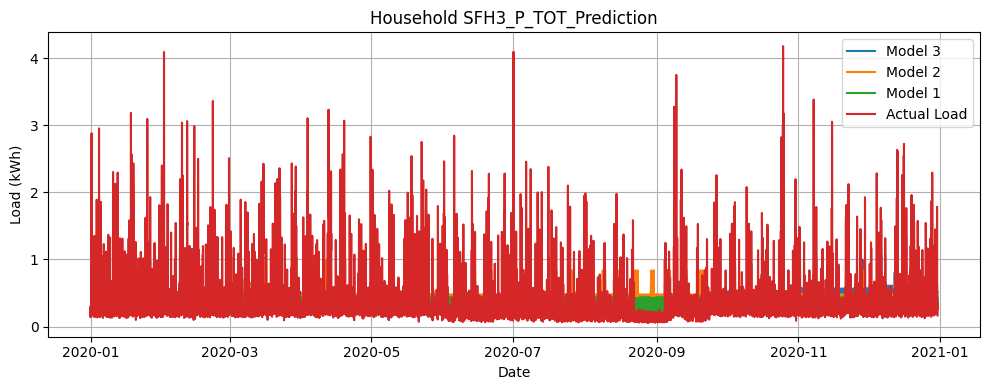

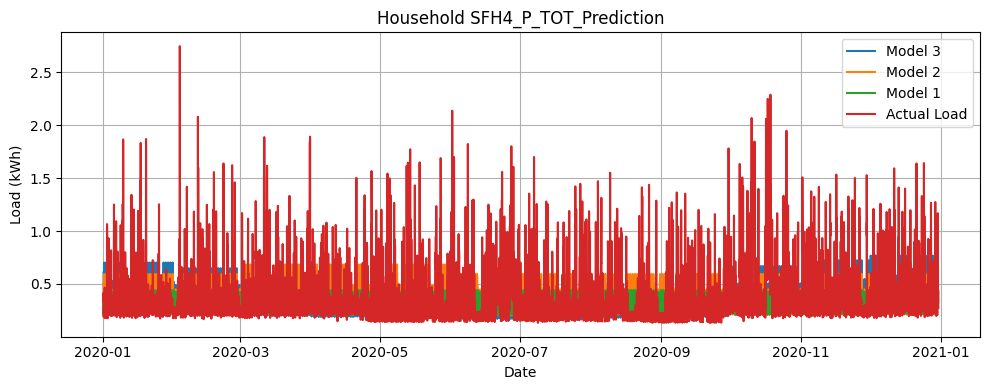

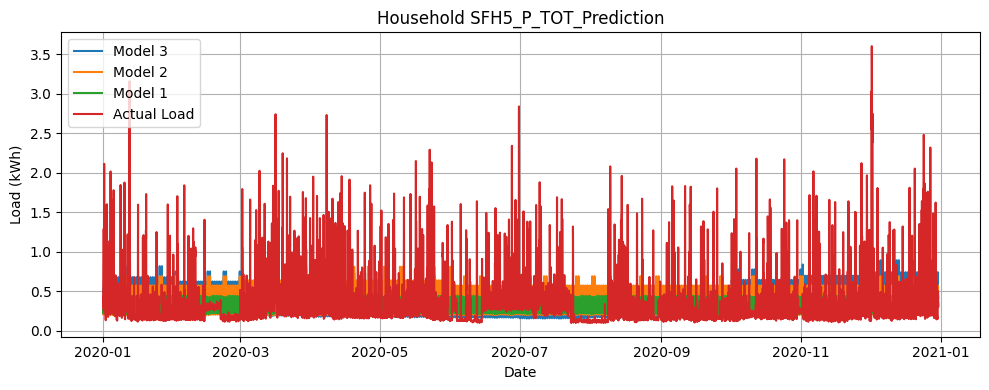

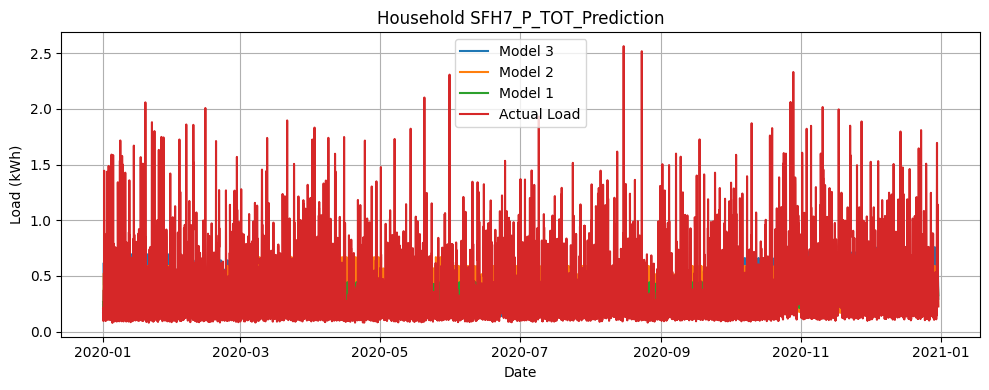

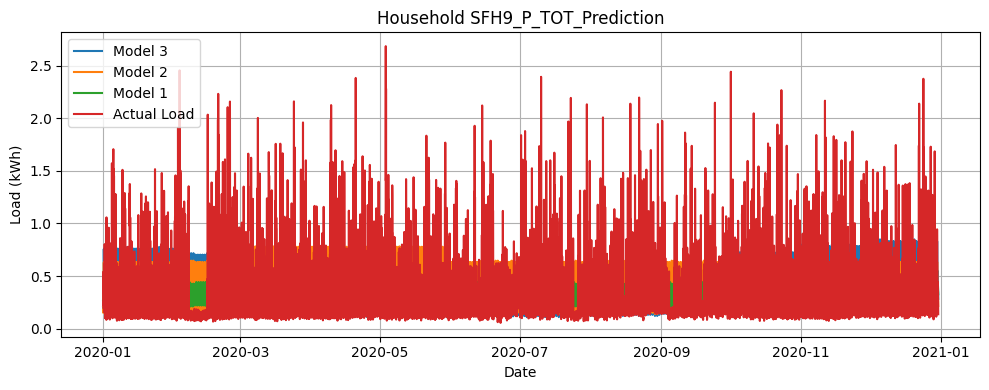

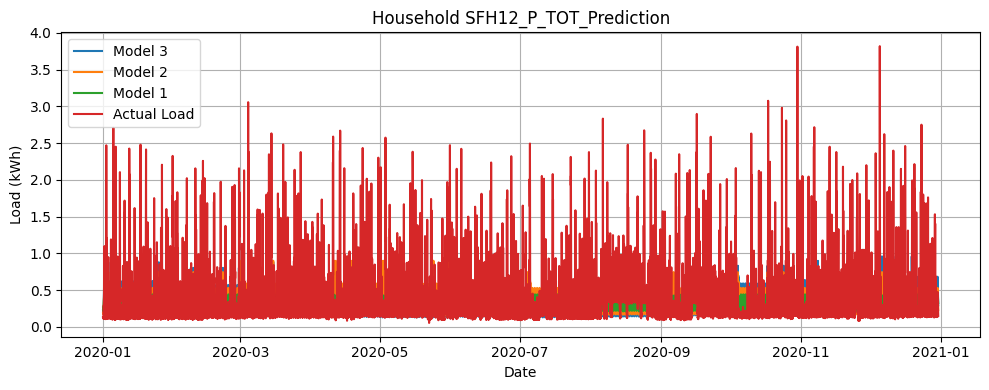

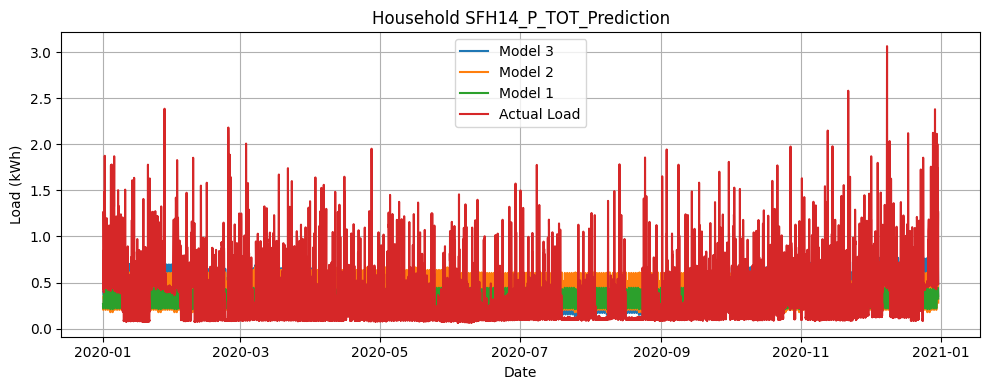

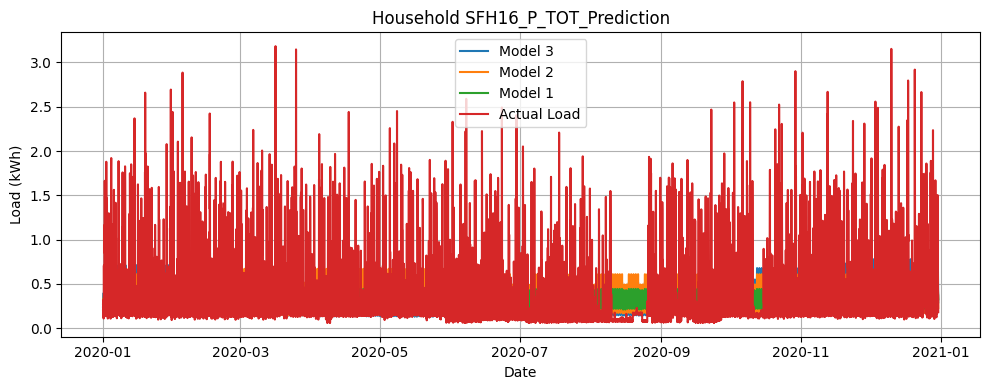

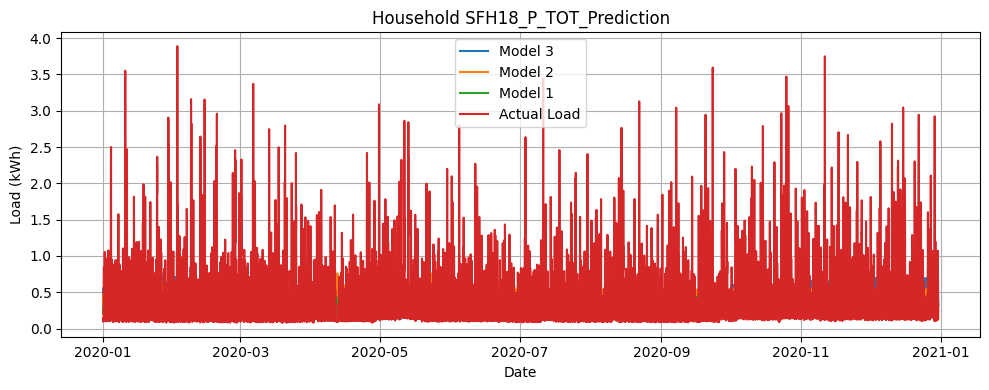

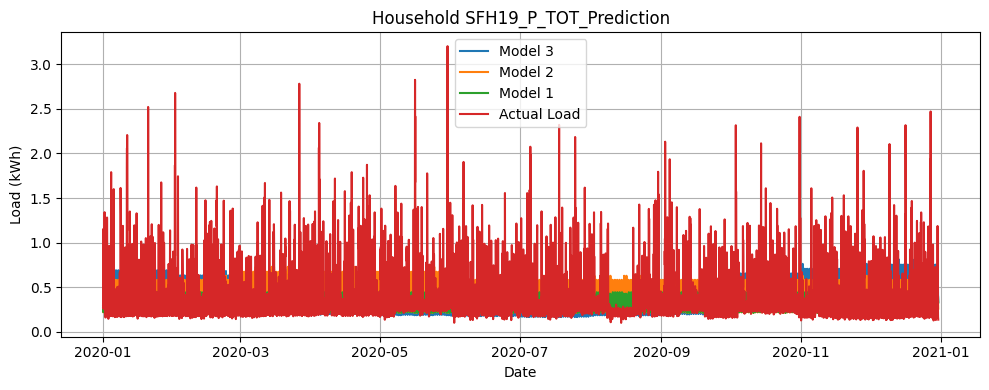

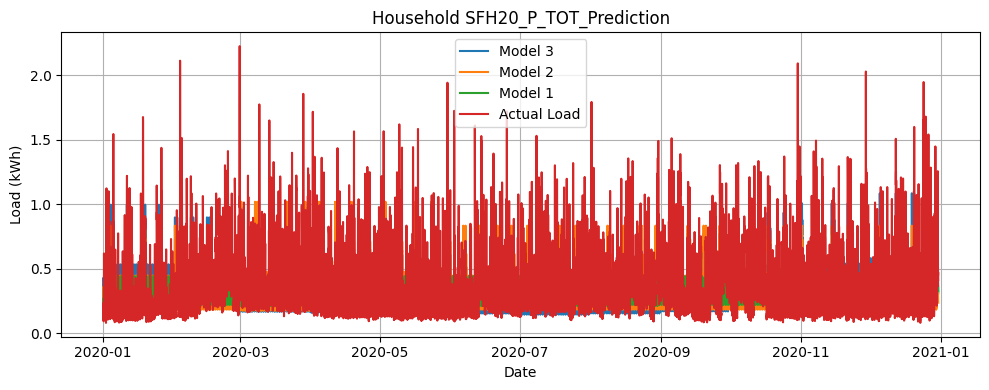

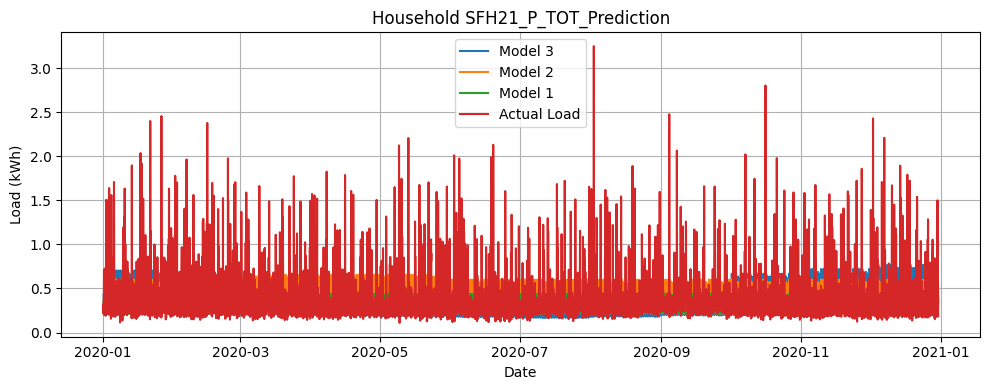

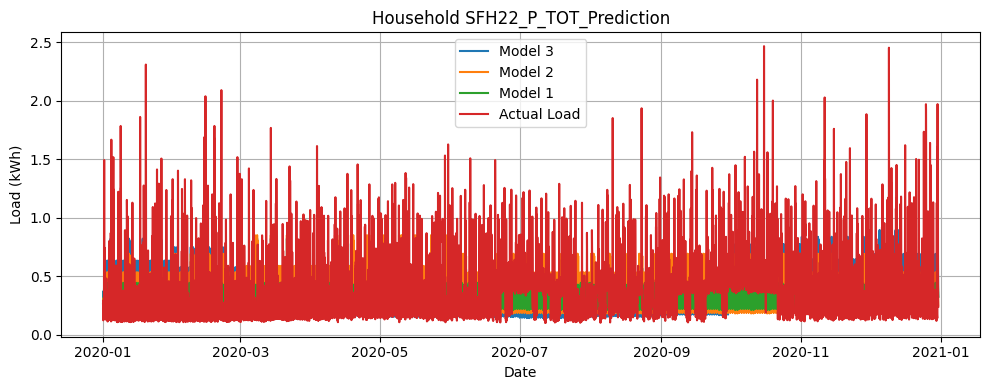

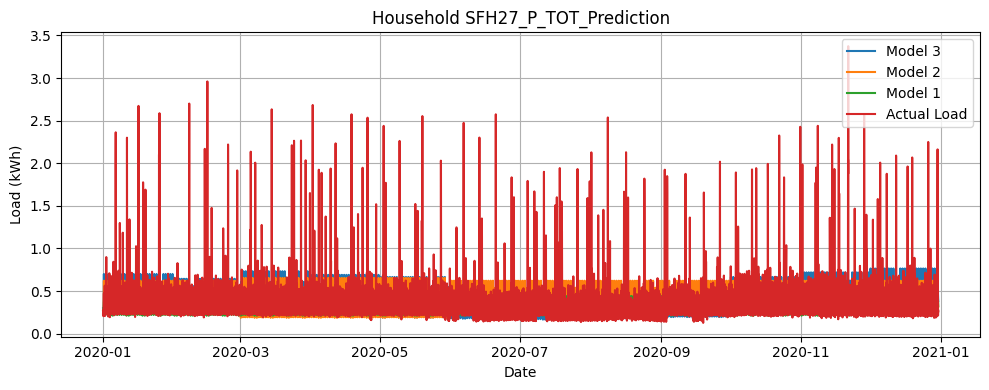

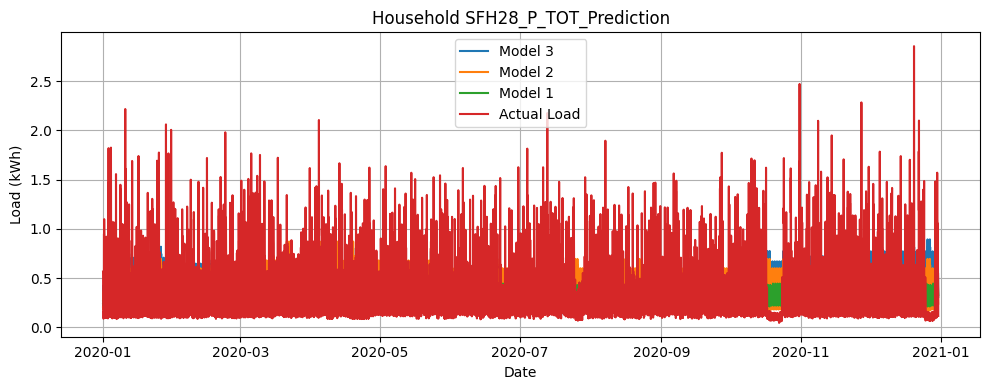

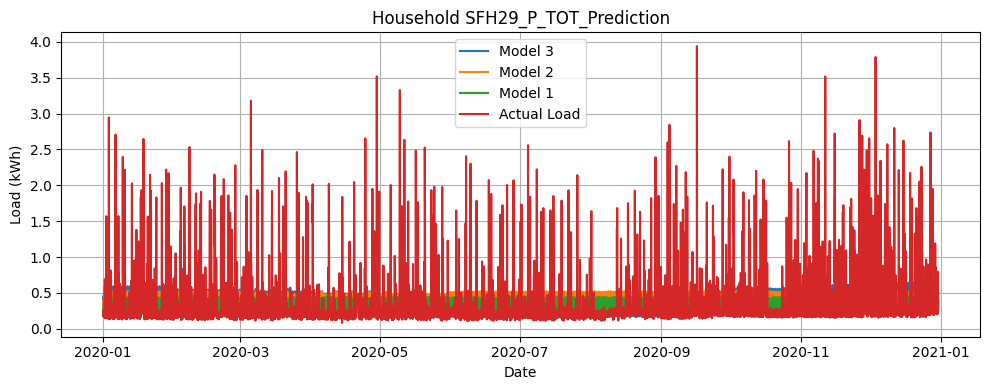

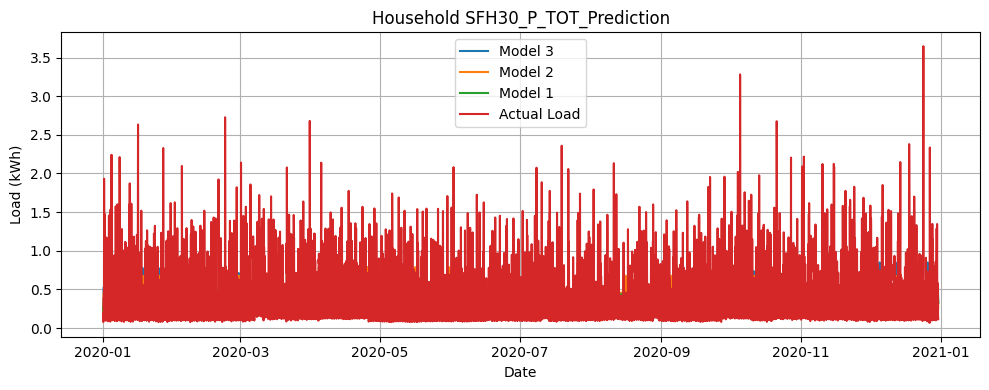

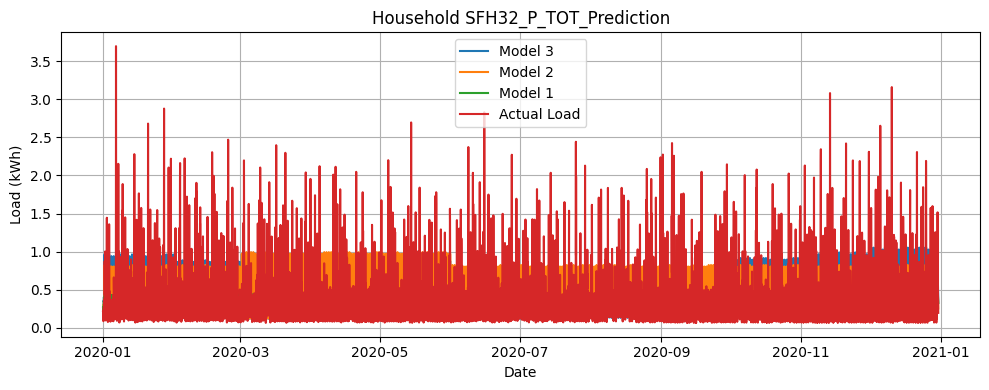

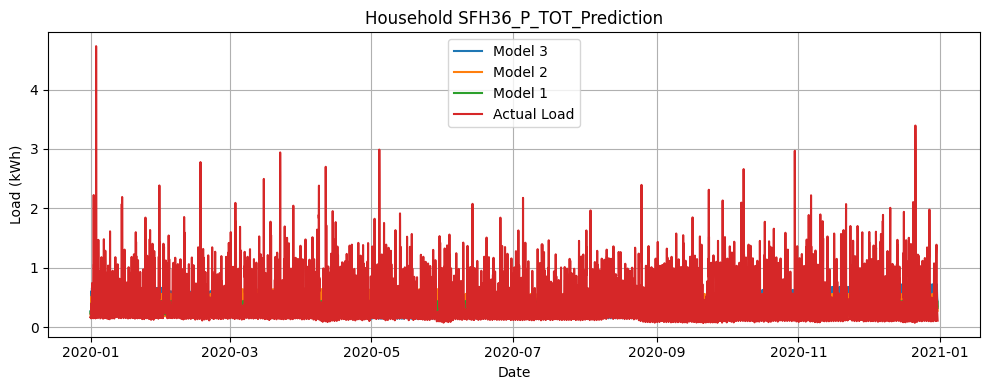

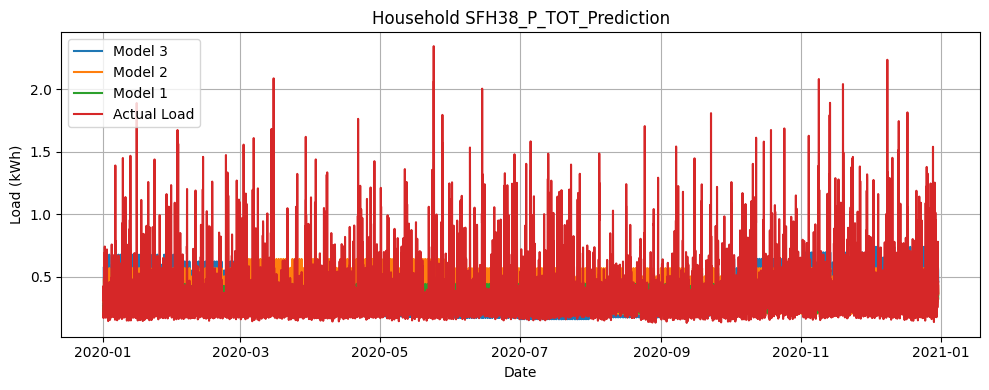

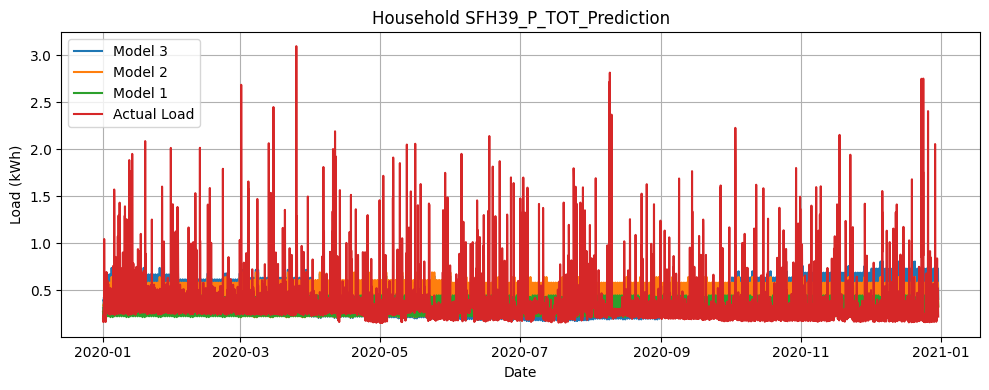

In [414]:
# Plot Predicted Load Profile for 2020 for each household

for household in model3_prediction_2020.columns:
    plt.figure(figsize=(10, 4))
    plt.plot(model3_prediction_2020.index, model3_prediction_2020[household], label="Model 3")
    plt.plot(model2_prediction_2020.index, model2_prediction_2020[household], label="Model 2")
    plt.plot(model1_prediciton_2020.index, model1_prediciton_2020['H00_predicted [kWh]'], label="Model 1")
    plt.plot(filtered_df_test.index, filtered_df_test[household.replace('_Prediction', '')], label="Actual Load")
    plt.title(f'Household {household}')
    plt.xlabel('Date')
    plt.ylabel('Load (kWh)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


